In [1]:
%load_ext autoreload
%autoreload 2
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from src.config import *
from src.utils import *
from src.experiments import run_experiment, show, augmented_cv

# Trying to solve the multiclass problem with data augmentation

### Load the augmented dataset (the features extracted)

In [2]:
train = pd.read_csv(MULTI_FEATURES_TRAIN_CSV)
aug = pd.read_csv(MULTI_FEATURES_AUG_CSV)
feature_cols = [c for c in train.columns if c not in ("filename", "label")]

print("Augmented images per class:", aug["label"].map(MULTI_CLASS_NAMES).value_counts().to_dict())
print("All sources are training images:", aug["source_filename"].isin(train["filename"]).all())
print("Copies per source:", aug.groupby("source_filename").size().unique())
total = train["label"].value_counts().add(aug["label"].value_counts(), fill_value=0).astype(int)
print("Training images per class with augmentation:", {MULTI_CLASS_NAMES[k]: v for k, v in total.items()})

Augmented images per class: {'scc': 1504}
All sources are training images: True
Copies per source: [4]
Training images per class with augmentation: {'mel': 2713, 'bcc': 1993, 'scc': 1880}


In [3]:
counts = pd.DataFrame({
    "original": train["label"].value_counts(),
    "augmented copies": aug["label"].value_counts(),
}).fillna(0).astype(int)
counts["with augmentation"] = counts["original"] + counts["augmented copies"]
counts.index = counts.index.map(MULTI_CLASS_NAMES)

percent = (100 * counts[["original", "with augmentation"]] / counts[["original", "with augmentation"]].sum()).round(1)
display(counts.join(percent, rsuffix=" %"))

,original,augmented copies,with augmentation,original %,with augmentation %
label,,,,,
mel,2713,0,2713,53.4,41.2
bcc,1993,0,1993,39.2,30.3
scc,376,1504,1880,7.4,28.5


And let's display some results of th augmentation:

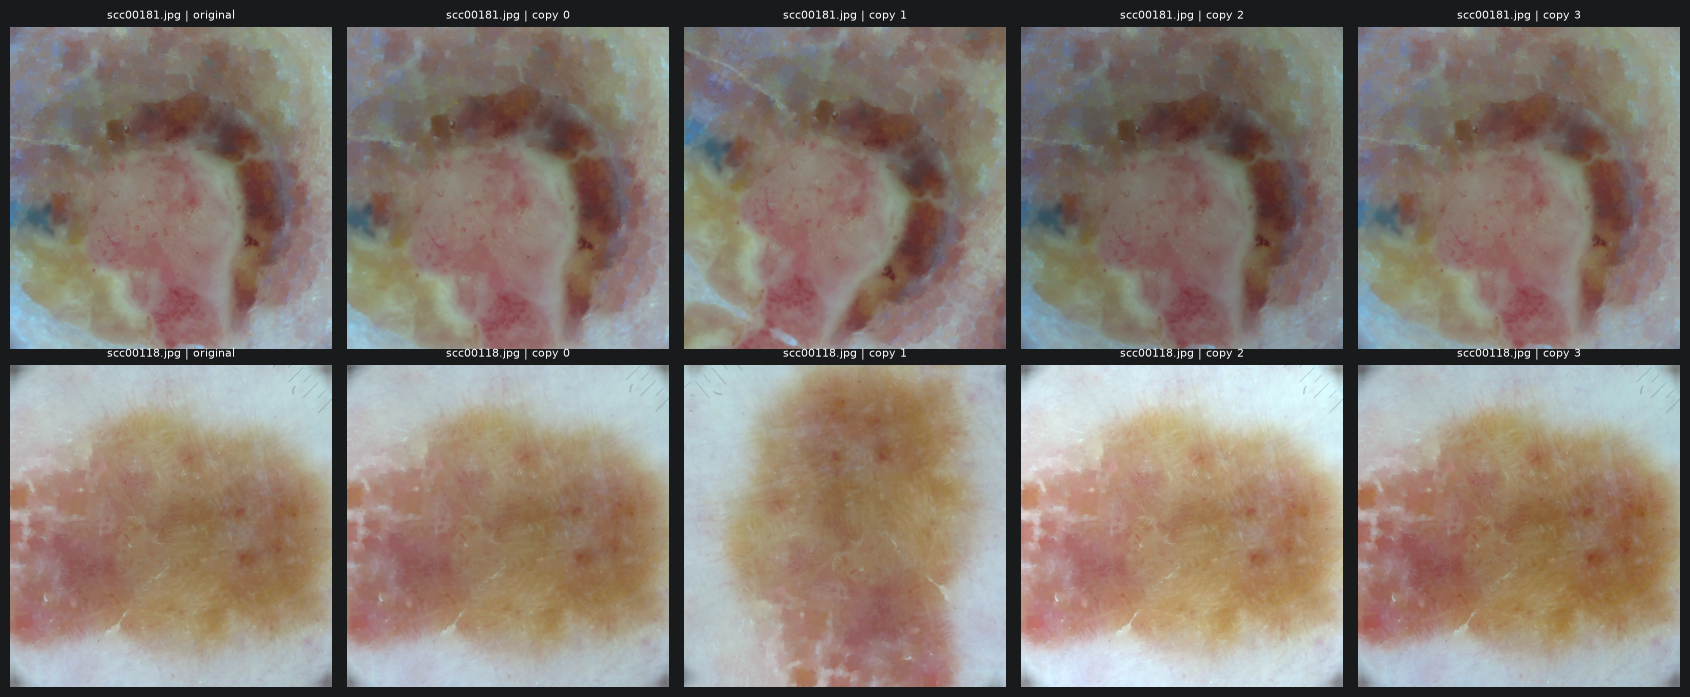

In [4]:
def load_aug(name, label):
    img = cv2.imread(str(MULTI_AUG_DIR / MULTI_CLASS_FOLDERS[label] / name))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

copies = aug.groupby("source_filename")["filename"].apply(list)
sources = copies.sample(2, random_state=np.random.randint(1000)).index

fig, axes = plt.subplots(2, 5, figsize=(17, 7))
for row, src in zip(axes, sources):
    imgs = [load_preprocessed(src, 2, MULTI_PREPROC_TRAIN_DIR, MULTI_CLASS_FOLDERS)]
    imgs += [load_aug(name, 2) for name in copies[src]]
    for ax, img, title in zip(row, imgs, ["original"] + [f"copy {k}" for k in range(4)]):
        ax.imshow(img); ax.set_title(f"{src} | {title}", fontsize=8); ax.axis("off")
plt.tight_layout()
plt.show()

### Check that the transformations produced images whose features are a certain distance away from their original image

Median distance copy -> its original:  5.1
Median distance between two scc images: 16.5


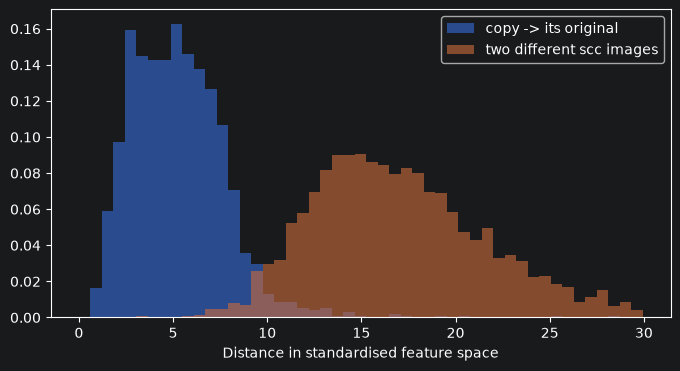

In [5]:
scaler = StandardScaler().fit(train[feature_cols])          # only for this check, not used by the best_final_models
Z_orig = pd.DataFrame(scaler.transform(train[feature_cols]), index=train["filename"])
Z_aug = scaler.transform(aug[feature_cols])

# distance of each copy to its own original
d_copy = np.linalg.norm(Z_aug - Z_orig.loc[aug["source_filename"]].values, axis=1)

# distance between two different real scc images
Z_scc = Z_orig[train["label"].values == 2].values
rng = np.random.default_rng(RANDOM_STATE)
i, j = rng.integers(0, len(Z_scc), (2, 3000))
d_pairs = np.linalg.norm(Z_scc[i[i != j]] - Z_scc[j[i != j]], axis=1)

print(f"Median distance copy -> its original:  {np.median(d_copy):.1f}")
print(f"Median distance between two scc images: {np.median(d_pairs):.1f}")

bins = np.linspace(0, np.percentile(d_pairs, 99), 50)
plt.figure(figsize=(8, 4))
plt.hist(d_copy, bins=bins, alpha=0.6, density=True, label="copy -> its original")
plt.hist(d_pairs, bins=bins, alpha=0.6, density=True, label="two different scc images")
plt.xlabel("Distance in standardised feature space")
plt.legend()
plt.show()

In [6]:
from sklearn.neighbors import NearestNeighbors

labels = train["label"].values
Z_tr = scaler.transform(train[feature_cols])
nn_scc = NearestNeighbors(n_neighbors=1).fit(Z_tr[labels == 2])
nn_bcc = NearestNeighbors(n_neighbors=1).fit(Z_tr[labels == 1])
closer_to_bcc = nn_bcc.kneighbors(Z_aug)[0].ravel() < nn_scc.kneighbors(Z_aug)[0].ravel()

per_transform = pd.DataFrame({"transform": aug["transform"],
                              "distance to original": d_copy,
                              "closer to bcc (%)": 100 * closer_to_bcc})
display(per_transform.groupby("transform")
        .agg({"distance to original": "median", "closer to bcc (%)": "mean"})
        .round(1))
print(f"All copies closer to a bcc than to any scc: {100 * closer_to_bcc.mean():.1f}%")

Copies closer to a real bcc than to any real scc: 12.2%


In [7]:
Z_scc = Z_tr[labels == 2]
Z_bcc = Z_tr[labels == 1]

d_scc = NearestNeighbors(n_neighbors=2).fit(Z_scc).kneighbors(Z_scc)[0][:, 1]   # nearest OTHER scc
d_bcc = NearestNeighbors(n_neighbors=1).fit(Z_bcc).kneighbors(Z_scc)[0].ravel()

print(f"Real scc closer to a bcc than to another scc: {np.mean(d_bcc < d_scc):.1%}")

Real scc closer to a bcc than to another scc: 47.9%


### Verifying that all the copies of one image stay in the same subset (no leakage from train to val)

In [9]:
X_all = np.vstack([train[feature_cols].values, aug[feature_cols].values])
y_all = np.concatenate([train["label"].values, aug["label"].values])
splits = augmented_cv(train["filename"], aug["source_filename"], y_all)

for k, (tr, te) in enumerate(splits):
    print(f"fold {k}: train {len(tr)} (scc {np.sum(y_all[tr] == 2)}) | test {len(te)} originals (scc {np.sum(y_all[te] == 2)})")

fold 0: train 5269 (scc 1505) | test 1017 originals (scc 75)
fold 1: train 5265 (scc 1500) | test 1017 originals (scc 76)
fold 2: train 5270 (scc 1505) | test 1016 originals (scc 75)
fold 3: train 5270 (scc 1505) | test 1016 originals (scc 75)
fold 4: train 5270 (scc 1505) | test 1016 originals (scc 75)


### Train our 6 models and report Kappa on cross-validation. Hyperparameters for each model are optimized based on this Kappa metric.

#### M2: Data augmentation

In [12]:
table_m2, fitted_m2 = run_experiment("M2 augmentation", X_all, y_all, task="multiclass", cv=splits)
show(table_m2, task="multiclass")

[M2 augmentation] LogReg: kappa = 0.605
[M2 augmentation] Random Forest: kappa = 0.657
[M2 augmentation] HistGradBoost: kappa = 0.679
[M2 augmentation] SVM (RBF): kappa = 0.704
[M2 augmentation] XGBoost: kappa = 0.692
[M2 augmentation] CatBoost: kappa = 0.672


,experiment,model,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
0,M2 augmentation,LogReg,0.605 ﷿﷿﷿﷿﷿﷿ 0.021,0.858 ﷿﷿﷿﷿﷿﷿ 0.014,0.740 ﷿﷿﷿﷿﷿﷿ 0.022,0.388 ﷿﷿﷿﷿﷿﷿ 0.047,0.651 ﷿﷿﷿﷿﷿﷿ 0.020
1,M2 augmentation,Random Forest,0.657 ﷿﷿﷿﷿﷿﷿ 0.011,0.881 ﷿﷿﷿﷿﷿﷿ 0.013,0.782 ﷿﷿﷿﷿﷿﷿ 0.016,0.428 ﷿﷿﷿﷿﷿﷿ 0.042,0.693 ﷿﷿﷿﷿﷿﷿ 0.011
2,M2 augmentation,HistGradBoost,0.679 ﷿﷿﷿﷿﷿﷿ 0.013,0.886 ﷿﷿﷿﷿﷿﷿ 0.016,0.819 ﷿﷿﷿﷿﷿﷿ 0.025,0.380 ﷿﷿﷿﷿﷿﷿ 0.064,0.699 ﷿﷿﷿﷿﷿﷿ 0.015
3,M2 augmentation,SVM (RBF),0.704 ﷿﷿﷿﷿﷿﷿ 0.015,0.917 ﷿﷿﷿﷿﷿﷿ 0.015,0.813 ﷿﷿﷿﷿﷿﷿ 0.020,0.399 ﷿﷿﷿﷿﷿﷿ 0.040,0.721 ﷿﷿﷿﷿﷿﷿ 0.008
4,M2 augmentation,XGBoost,0.692 ﷿﷿﷿﷿﷿﷿ 0.009,0.892 ﷿﷿﷿﷿﷿﷿ 0.018,0.825 ﷿﷿﷿﷿﷿﷿ 0.015,0.399 ﷿﷿﷿﷿﷿﷿ 0.056,0.710 ﷿﷿﷿﷿﷿﷿ 0.012
5,M2 augmentation,CatBoost,0.672 ﷿﷿﷿﷿﷿﷿ 0.017,0.886 ﷿﷿﷿﷿﷿﷿ 0.017,0.804 ﷿﷿﷿﷿﷿﷿ 0.015,0.399 ﷿﷿﷿﷿﷿﷿ 0.042,0.698 ﷿﷿﷿﷿﷿﷿ 0.015


#### M3: Data augmentation + class weighting

In [13]:
table_m3, fitted_m3 = run_experiment("M3 augmentation + weights", X_all, y_all, task="multiclass",
                                     weighted=True, cv=splits)
show(table_m3, task="multiclass")

[M3 augmentation + weights] LogReg: kappa = 0.605
[M3 augmentation + weights] Random Forest: kappa = 0.653
[M3 augmentation + weights] HistGradBoost: kappa = 0.687
[M3 augmentation + weights] SVM (RBF): kappa = 0.705
[M3 augmentation + weights] XGBoost: kappa = 0.692
[M3 augmentation + weights] CatBoost: kappa = 0.677


,experiment,model,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
0,M3 augmentation + weights,LogReg,0.605 ﷿﷿﷿﷿﷿﷿ 0.021,0.858 ﷿﷿﷿﷿﷿﷿ 0.014,0.740 ﷿﷿﷿﷿﷿﷿ 0.022,0.388 ﷿﷿﷿﷿﷿﷿ 0.047,0.651 ﷿﷿﷿﷿﷿﷿ 0.020
1,M3 augmentation + weights,Random Forest,0.653 ﷿﷿﷿﷿﷿﷿ 0.012,0.865 ﷿﷿﷿﷿﷿﷿ 0.018,0.793 ﷿﷿﷿﷿﷿﷿ 0.014,0.439 ﷿﷿﷿﷿﷿﷿ 0.034,0.692 ﷿﷿﷿﷿﷿﷿ 0.011
2,M3 augmentation + weights,HistGradBoost,0.687 ﷿﷿﷿﷿﷿﷿ 0.015,0.884 ﷿﷿﷿﷿﷿﷿ 0.020,0.827 ﷿﷿﷿﷿﷿﷿ 0.015,0.407 ﷿﷿﷿﷿﷿﷿ 0.061,0.709 ﷿﷿﷿﷿﷿﷿ 0.015
3,M3 augmentation + weights,SVM (RBF),0.705 ﷿﷿﷿﷿﷿﷿ 0.015,0.910 ﷿﷿﷿﷿﷿﷿ 0.015,0.817 ﷿﷿﷿﷿﷿﷿ 0.019,0.420 ﷿﷿﷿﷿﷿﷿ 0.042,0.724 ﷿﷿﷿﷿﷿﷿ 0.009
4,M3 augmentation + weights,XGBoost,0.692 ﷿﷿﷿﷿﷿﷿ 0.010,0.895 ﷿﷿﷿﷿﷿﷿ 0.022,0.819 ﷿﷿﷿﷿﷿﷿ 0.016,0.412 ﷿﷿﷿﷿﷿﷿ 0.062,0.712 ﷿﷿﷿﷿﷿﷿ 0.012
5,M3 augmentation + weights,CatBoost,0.677 ﷿﷿﷿﷿﷿﷿ 0.016,0.888 ﷿﷿﷿﷿﷿﷿ 0.019,0.810 ﷿﷿﷿﷿﷿﷿ 0.015,0.393 ﷿﷿﷿﷿﷿﷿ 0.033,0.700 ﷿﷿﷿﷿﷿﷿ 0.013


Let's show the conf matrices and ROC curves of the best models of each experiment (M2 and M3):

done: M2 augmentation - SVM (RBF)
done: M3 augmentation + weights - SVM (RBF)


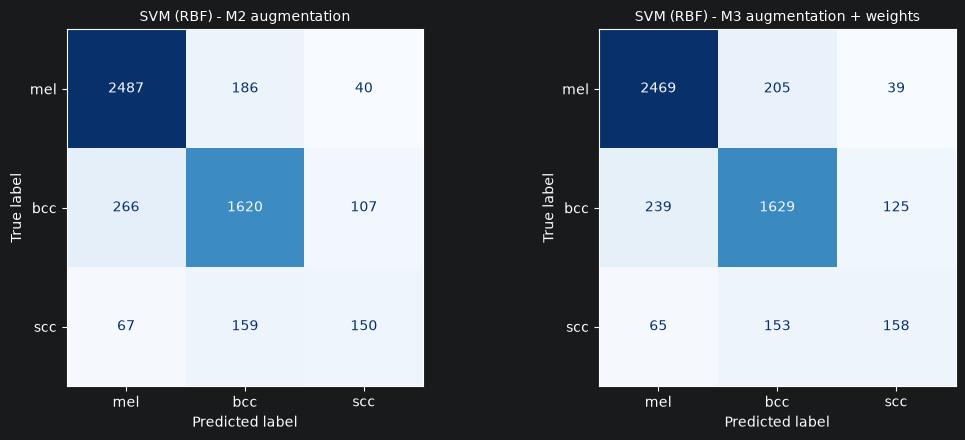

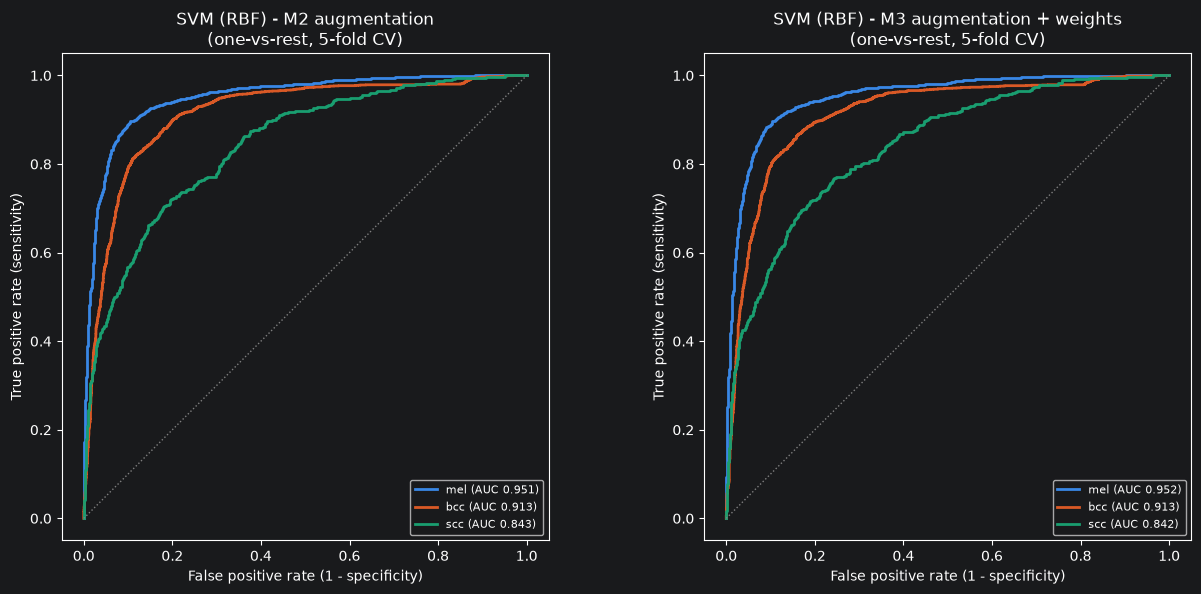

In [14]:
from src.experiments import oof_predictions

n = len(train)                    # rows 0..n-1 are the originals; only those are in the test folds
y_orig = y_all[:n]

best_aug = {}
for table, fitted in [(table_m2, fitted_m2), (table_m3, fitted_m3)]:
    r = table.loc[table["kappa"].idxmax()]
    pred, scores = oof_predictions(fitted[r["model"]], X_all, y_all, cv=splits)
    best_aug[(r["experiment"], r["model"])] = (pred[:n], scores[:n])
    print("done:", r["experiment"], "-", r["model"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ((exp, model), (pred, _)) in zip(axes, best_aug.items()):
    plot_confusion(ax, y_orig, pred, f"{model} - {exp}", class_names=MULTI_CLASS_NAMES.values())
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, ((exp, model), (_, scores)) in zip(axes, best_aug.items()):
    for label, name in MULTI_CLASS_NAMES.items():
        plot_roc(ax, (y_orig == label).astype(int), scores[:, label], name, MULTI_CLASS_COLORS[label])
    finish_roc(ax, f"{model} - {exp}\n(one-vs-rest, 5-fold CV)")
plt.tight_layout()
plt.show()

### Summary of results of all the experiments (M0 - M1 - M2 - M3)

In [15]:
baseline = pd.read_csv(MULTI_RESULTS_DIR / "multi_exp_baseline.csv")
table_aug = pd.concat([table_m2, table_m3], ignore_index=True)
table_aug.to_csv(MULTI_RESULTS_DIR / "multi_exp_augmentation.csv", index=False)

all_m = pd.concat([baseline, table_aug], ignore_index=True)
display(show(all_m.sort_values("kappa", ascending=False), task="multiclass"))

best = all_m.loc[all_m["kappa"].idxmax()]
print(f"Best by CV kappa: {best['model']} ({best['experiment']}) - kappa {best['kappa']:.3f}")

,experiment,model,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
3,M0 no handling,SVM (RBF),0.720 ﷿﷿﷿﷿﷿﷿ 0.015,0.923 ﷿﷿﷿﷿﷿﷿ 0.013,0.838 ﷿﷿﷿﷿﷿﷿ 0.022,0.367 ﷿﷿﷿﷿﷿﷿ 0.054,0.736 ﷿﷿﷿﷿﷿﷿ 0.014
9,M1 class weights,SVM (RBF),0.717 ﷿﷿﷿﷿﷿﷿ 0.017,0.926 ﷿﷿﷿﷿﷿﷿ 0.016,0.839 ﷿﷿﷿﷿﷿﷿ 0.020,0.327 ﷿﷿﷿﷿﷿﷿ 0.065,0.724 ﷿﷿﷿﷿﷿﷿ 0.022
21,M3 augmentation + weights,SVM (RBF),0.705 ﷿﷿﷿﷿﷿﷿ 0.015,0.910 ﷿﷿﷿﷿﷿﷿ 0.015,0.817 ﷿﷿﷿﷿﷿﷿ 0.019,0.420 ﷿﷿﷿﷿﷿﷿ 0.042,0.724 ﷿﷿﷿﷿﷿﷿ 0.009
15,M2 augmentation,SVM (RBF),0.704 ﷿﷿﷿﷿﷿﷿ 0.015,0.917 ﷿﷿﷿﷿﷿﷿ 0.015,0.813 ﷿﷿﷿﷿﷿﷿ 0.020,0.399 ﷿﷿﷿﷿﷿﷿ 0.040,0.721 ﷿﷿﷿﷿﷿﷿ 0.008
10,M1 class weights,XGBoost,0.697 ﷿﷿﷿﷿﷿﷿ 0.012,0.890 ﷿﷿﷿﷿﷿﷿ 0.018,0.864 ﷿﷿﷿﷿﷿﷿ 0.013,0.287 ﷿﷿﷿﷿﷿﷿ 0.031,0.700 ﷿﷿﷿﷿﷿﷿ 0.012
8,M1 class weights,HistGradBoost,0.694 ﷿﷿﷿﷿﷿﷿ 0.012,0.902 ﷿﷿﷿﷿﷿﷿ 0.017,0.868 ﷿﷿﷿﷿﷿﷿ 0.015,0.186 ﷿﷿﷿﷿﷿﷿ 0.047,0.668 ﷿﷿﷿﷿﷿﷿ 0.018
4,M0 no handling,XGBoost,0.694 ﷿﷿﷿﷿﷿﷿ 0.010,0.905 ﷿﷿﷿﷿﷿﷿ 0.017,0.865 ﷿﷿﷿﷿﷿﷿ 0.020,0.181 ﷿﷿﷿﷿﷿﷿ 0.032,0.666 ﷿﷿﷿﷿﷿﷿ 0.013
22,M3 augmentation + weights,XGBoost,0.692 ﷿﷿﷿﷿﷿﷿ 0.010,0.895 ﷿﷿﷿﷿﷿﷿ 0.022,0.819 ﷿﷿﷿﷿﷿﷿ 0.016,0.412 ﷿﷿﷿﷿﷿﷿ 0.062,0.712 ﷿﷿﷿﷿﷿﷿ 0.012
16,M2 augmentation,XGBoost,0.692 ﷿﷿﷿﷿﷿﷿ 0.009,0.892 ﷿﷿﷿﷿﷿﷿ 0.018,0.825 ﷿﷿﷿﷿﷿﷿ 0.015,0.399 ﷿﷿﷿﷿﷿﷿ 0.056,0.710 ﷿﷿﷿﷿﷿﷿ 0.012
20,M3 augmentation + weights,HistGradBoost,0.687 ﷿﷿﷿﷿﷿﷿ 0.015,0.884 ﷿﷿﷿﷿﷿﷿ 0.020,0.827 ﷿﷿﷿﷿﷿﷿ 0.015,0.407 ﷿﷿﷿﷿﷿﷿ 0.061,0.709 ﷿﷿﷿﷿﷿﷿ 0.015


Best by CV kappa: SVM (RBF) (M0 no handling) - kappa 0.720


### Saving the best model

In [16]:
import ast, re, joblib
from src.experiments import build_models

best = all_m.loc[all_m["kappa"].idxmax()]

# Hyperparameters chosen by CV (read back from the CSV as text for M0/M1)
params = best["params"]
if isinstance(params, str):
    params = ast.literal_eval(re.sub(r"np\.float64\(([^)]*)\)", r"\1", params))

weighted = "weights" in best["experiment"]
augmented = "augmentation" in best["experiment"]

model = build_models(weighted=weighted)[best["model"]].set_params(**params)
X_fit, y_fit = (X_all, y_all) if augmented else (train[feature_cols].values, train["label"].values)
model.fit(X_fit, y_fit)

MODELS_DIR.mkdir(exist_ok=True)
joblib.dump({
    "model":        model,                                   # scaler + classifier, trained on all of train
    "experiment":   best["experiment"],
    "model_name":   best["model"],
    "params":       params,
    "feature_cols": feature_cols,
    "class_names":  MULTI_CLASS_NAMES,
    "train_data":   "originals + augmented scc" if augmented else "originals",
    "cv_scores":    {m: best[m] for m in ["kappa", "recall_mel", "recall_bcc", "recall_scc", "f1_macro"]},
}, MODELS_DIR / "multi_best_v1.joblib")

print(f"Saved: {best['model']} ({best['experiment']}) - CV kappa {best['kappa']:.3f}")
print("Params:", params)

Saved: SVM (RBF) (M0 no handling) - CV kappa 0.720
Params: {'clf__C': 6.358358856676251, 'clf__gamma': 0.013311216080736894}
